In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import warnings
warnings.filterwarnings("ignore")

In [4]:
df =pd.read_csv("synthetic_hvac_predictive_maintenance.csv")

In [3]:
df.head()

,timestamp,equipment_id,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure
0,2025-01-01 00:00:00,HVAC-01,27.81,57.73,1.504,7.75,6.12,7,1147.2,2723,0
1,2025-01-01 01:00:00,HVAC-02,19.38,51.20,1.198,6.59,5.70,21,1190.2,23230,0
2,2025-01-01 02:00:00,HVAC-03,18.73,68.29,2.059,8.45,6.24,24,1561.6,19655,0
3,2025-01-01 03:00:00,HVAC-04,25.30,42.75,0.896,7.76,4.76,12,1328.6,13194,0
4,2025-01-01 04:00:00,HVAC-05,27.94,66.79,1.355,10.32,4.46,7,1284.7,13019,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               3000 non-null   object 
 1   equipment_id            3000 non-null   object 
 2   temperature_c           2970 non-null   float64
 3   humidity_pct            2970 non-null   float64
 4   vibration_mm_s          2970 non-null   float64
 5   pressure_bar            2970 non-null   float64
 6   energy_consumption_kwh  2970 non-null   float64
 7   runtime_hours_per_day   3000 non-null   int64  
 8   airflow_m3_h            3000 non-null   float64
 9   equipment_age_hours     3000 non-null   int64  
 10  failure                 3000 non-null   int64  
dtypes: float64(6), int64(3), object(2)
memory usage: 257.9+ KB


In [5]:
df.shape

(3000, 11)

In [6]:
df.describe(include='all')

,timestamp,equipment_id,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure
count,3000,3000,2970.000000,2970.000000,2970.000000,2970.000000,2970.000000,3000.000000,3000.000000,3000.000000,3000.000000
unique,3000,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2025-01-01 00:00:00,HVAC-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,22.918906,52.230727,1.405710,7.175707,4.518306,12.443667,1211.066167,15058.286333,0.151333
std,NaN,NaN,4.988123,14.989676,0.679792,1.197493,1.095912,6.996652,221.541313,8674.794715,0.358433
min,NaN,NaN,8.000000,15.000000,0.262000,3.460000,1.000000,1.000000,500.000000,65.000000,0.000000
25%,NaN,NaN,19.530000,42.082500,0.941250,6.380000,3.780000,6.000000,1055.525000,7489.000000,0.000000
50%,NaN,NaN,22.960000,51.885000,1.258000,7.160000,4.490000,12.000000,1208.950000,14950.000000,0.000000
75%,NaN,NaN,26.197500,62.440000,1.715750,7.960000,5.267500,18.000000,1362.300000,22643.250000,0.000000


In [7]:
df.isnull().sum()

timestamp                  0
equipment_id               0
temperature_c             30
humidity_pct              30
vibration_mm_s            30
pressure_bar              30
energy_consumption_kwh    30
runtime_hours_per_day      0
airflow_m3_h               0
equipment_age_hours        0
failure                    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['failure'].value_counts()

failure
0    2546
1     454
Name: count, dtype: int64

In [8]:

sensor_columns = [
    "temperature_c",
    "humidity_pct",
    "vibration_mm_s",
    "pressure_bar",
    "energy_consumption_kwh"
]


In [9]:
for col in sensor_columns:
    print(col,df[col].median())

temperature_c 22.96
humidity_pct 51.885000000000005
vibration_mm_s 1.258
pressure_bar 7.16
energy_consumption_kwh 4.49


In [10]:
for col in sensor_columns:
    df[col] = df[col].fillna(df[col].median())

In [11]:
df.isnull().sum()

timestamp                 0
equipment_id              0
temperature_c             0
humidity_pct              0
vibration_mm_s            0
pressure_bar              0
energy_consumption_kwh    0
runtime_hours_per_day     0
airflow_m3_h              0
equipment_age_hours       0
failure                   0
dtype: int64

In [12]:
df.describe(include='all')

,timestamp,equipment_id,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure
count,3000,3000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
unique,3000,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2025-01-01 00:00:00,HVAC-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,22.919317,52.227270,1.404233,7.17555,4.518023,12.443667,1211.066167,15058.286333,0.151333
std,NaN,NaN,4.963113,14.914554,0.676544,1.19149,1.090421,6.996652,221.541313,8674.794715,0.358433
min,NaN,NaN,8.000000,15.000000,0.262000,3.46000,1.000000,1.000000,500.000000,65.000000,0.000000
25%,NaN,NaN,19.550000,42.260000,0.945000,6.38000,3.790000,6.000000,1055.525000,7489.000000,0.000000
50%,NaN,NaN,22.960000,51.885000,1.258000,7.16000,4.490000,12.000000,1208.950000,14950.000000,0.000000
75%,NaN,NaN,26.160000,62.272500,1.710000,7.95000,5.260000,18.000000,1362.300000,22643.250000,0.000000


In [16]:

sensor_columns = [
    "temperature_c",
    "humidity_pct",
    "vibration_mm_s",
    "pressure_bar",
    "energy_consumption_kwh",
    "runtime_hours_per_day",
    "airflow_m3_h",
    "equipment_age_hours"
]


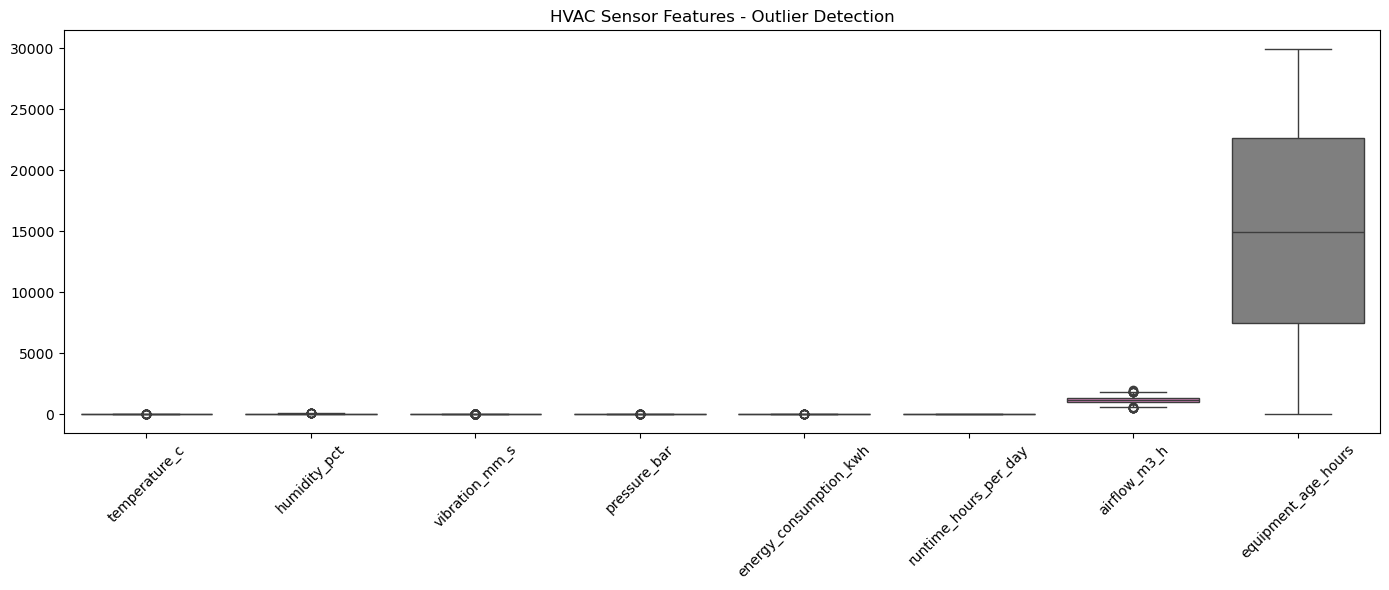

In [17]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[sensor_columns])

plt.xticks(rotation=45)
plt.title("HVAC Sensor Features - Outlier Detection")
plt.tight_layout()
plt.show()


In [19]:
for col in sensor_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} potential outliers")

temperature_c: 27 potential outliers
humidity_pct: 11 potential outliers
vibration_mm_s: 107 potential outliers
pressure_bar: 30 potential outliers
energy_consumption_kwh: 13 potential outliers
runtime_hours_per_day: 0 potential outliers
airflow_m3_h: 15 potential outliers
equipment_age_hours: 0 potential outliers


In [21]:
for col in sensor_columns:
    df_clean = df.copy()
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )


In [25]:
for col in sensor_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ).sum()
print(f"{col}: {count} outliers")

    

equipment_age_hours: 0 outliers


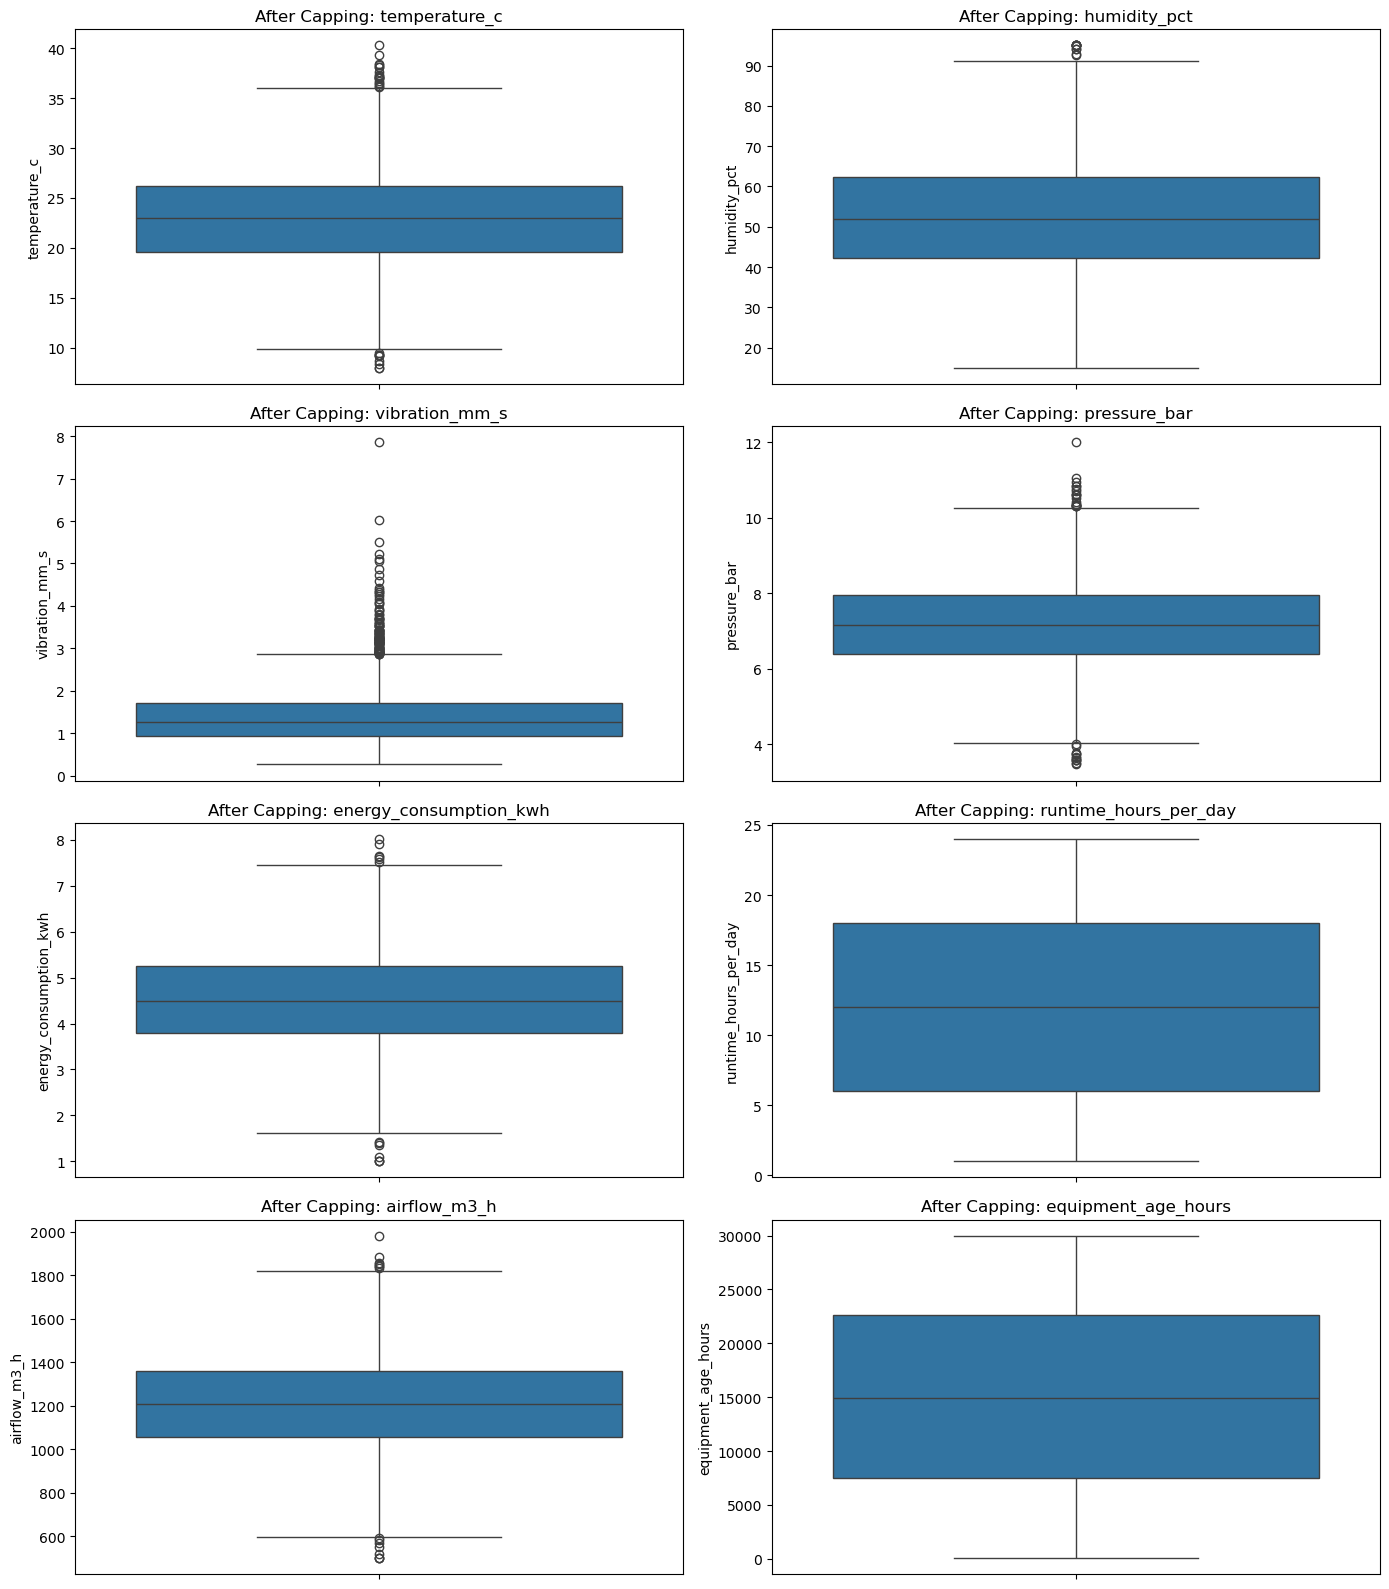

In [26]:


fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, col in zip(axes.flatten(), sensor_columns):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"After Capping: {col}")

plt.tight_layout()
plt.show()

In [27]:
for col in sensor_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_clean[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Capping completed using original IQR limits.")

Capping completed using original IQR limits.


In [28]:
for col in sensor_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ).sum()

    print(f"{col}: {count} outliers after capping")

temperature_c: 0 outliers after capping
humidity_pct: 0 outliers after capping
vibration_mm_s: 0 outliers after capping
pressure_bar: 0 outliers after capping
energy_consumption_kwh: 0 outliers after capping
runtime_hours_per_day: 0 outliers after capping
airflow_m3_h: 0 outliers after capping
equipment_age_hours: 0 outliers after capping


In [29]:
df_clean.describe(include='all')

,timestamp,equipment_id,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure
count,3000,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
unique,3000,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2025-01-01 00:00:00,HVAC-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,22.913215,52.219485,1.380607,7.174787,4.518462,12.443667,1211.102312,15058.286333,0.151333
std,NaN,NaN,4.931946,14.892975,0.593936,1.181318,1.086198,6.996652,220.752598,8674.794715,0.358433
min,NaN,NaN,9.635000,15.000000,0.262000,4.025000,1.585000,1.000000,595.362500,65.000000,0.000000
25%,NaN,NaN,19.550000,42.260000,0.945000,6.380000,3.790000,6.000000,1055.525000,7489.000000,0.000000
50%,NaN,NaN,22.960000,51.885000,1.258000,7.160000,4.490000,12.000000,1208.950000,14950.000000,0.000000
75%,NaN,NaN,26.160000,62.272500,1.710000,7.950000,5.260000,18.000000,1362.300000,22643.250000,0.000000


In [30]:
df_clean.shape

(3000, 11)

In [31]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               3000 non-null   object 
 1   equipment_id            3000 non-null   object 
 2   temperature_c           3000 non-null   float64
 3   humidity_pct            3000 non-null   float64
 4   vibration_mm_s          3000 non-null   float64
 5   pressure_bar            3000 non-null   float64
 6   energy_consumption_kwh  3000 non-null   float64
 7   runtime_hours_per_day   3000 non-null   int64  
 8   airflow_m3_h            3000 non-null   float64
 9   equipment_age_hours     3000 non-null   int64  
 10  failure                 3000 non-null   int64  
dtypes: float64(6), int64(3), object(2)
memory usage: 257.9+ KB


In [32]:
df_clean["failure"].value_counts()

failure
0    2546
1     454
Name: count, dtype: int64

In [33]:
df_clean["failure"].value_counts(normalize=True) * 100

failure
0    84.866667
1    15.133333
Name: proportion, dtype: float64

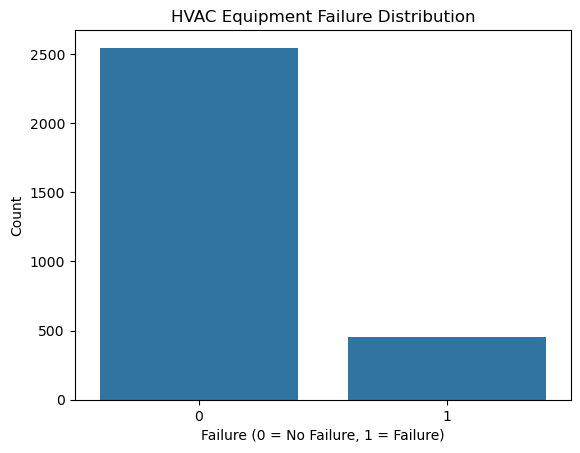

In [34]:
sns.countplot(data=df_clean, x="failure")
plt.title("HVAC Equipment Failure Distribution")
plt.xlabel("Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Count")
plt.show()


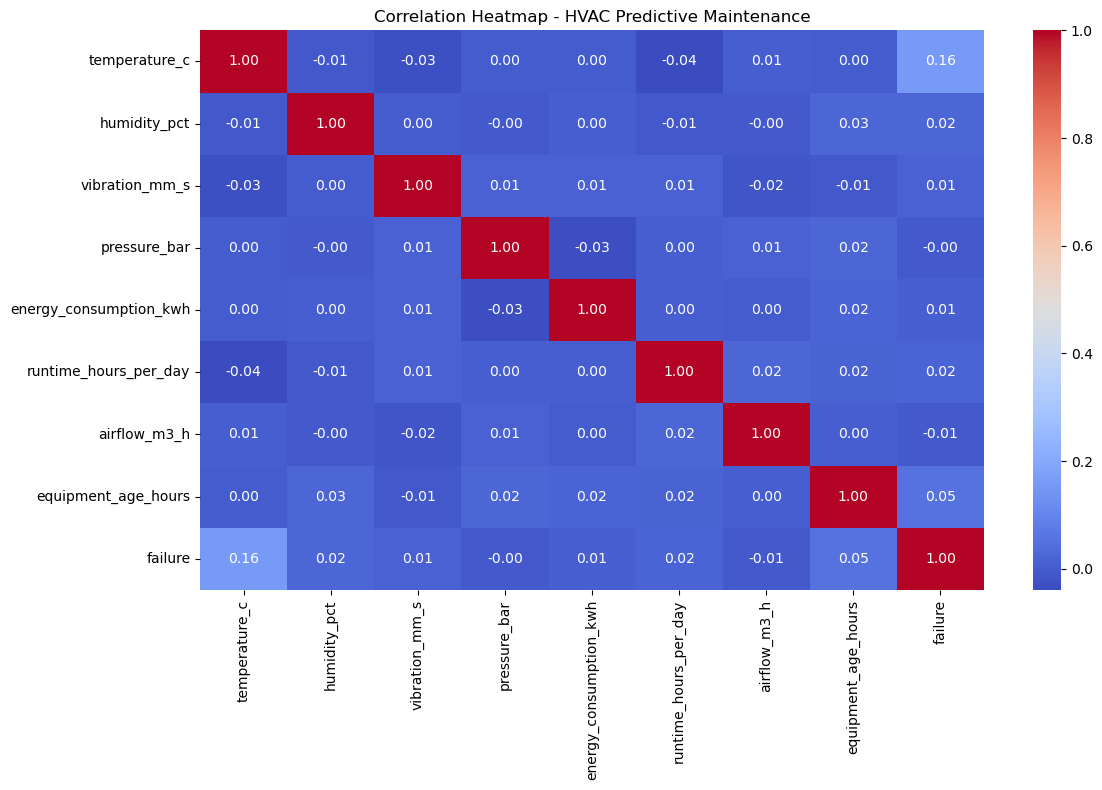

In [35]:
numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - HVAC Predictive Maintenance")
plt.tight_layout()
plt.show()

In [36]:

df_model = df_clean.copy()


df_model["timestamp"] = pd.to_datetime(df_model["timestamp"])


df_model["year"] = df_model["timestamp"].dt.year
df_model["month"] = df_model["timestamp"].dt.month
df_model["day"] = df_model["timestamp"].dt.day
df_model["hour"] = df_model["timestamp"].dt.hour

df_model.head()

,timestamp,equipment_id,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure,year,month,day,hour
0,2025-01-01 00:00:00,HVAC-01,27.81,57.73,1.504,7.750,6.12,7,1147.2,2723,0,2025,1,1,0
1,2025-01-01 01:00:00,HVAC-02,19.38,51.20,1.198,6.590,5.70,21,1190.2,23230,0,2025,1,1,1
2,2025-01-01 02:00:00,HVAC-03,18.73,68.29,2.059,8.450,6.24,24,1561.6,19655,0,2025,1,1,2
3,2025-01-01 03:00:00,HVAC-04,25.30,42.75,0.896,7.760,4.76,12,1328.6,13194,0,2025,1,1,3
4,2025-01-01 04:00:00,HVAC-05,27.94,66.79,1.355,10.305,4.46,7,1284.7,13019,0,2025,1,1,4


In [37]:
df_model = df_model.drop(
    columns=["timestamp", "equipment_id"],
    errors="ignore"
)

In [38]:
df_model.head()

,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,failure,year,month,day,hour
0,27.81,57.73,1.504,7.750,6.12,7,1147.2,2723,0,2025,1,1,0
1,19.38,51.20,1.198,6.590,5.70,21,1190.2,23230,0,2025,1,1,1
2,18.73,68.29,2.059,8.450,6.24,24,1561.6,19655,0,2025,1,1,2
3,25.30,42.75,0.896,7.760,4.76,12,1328.6,13194,0,2025,1,1,3
4,27.94,66.79,1.355,10.305,4.46,7,1284.7,13019,0,2025,1,1,4


In [39]:
X = df_model.drop(columns=["failure"])
y = df_model["failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3000, 12)
Target shape: (3000,)


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (2400, 12)
Testing features: (600, 12)

Training target distribution:
failure
0    0.84875
1    0.15125
Name: proportion, dtype: float64

Testing target distribution:
failure
0    0.848333
1    0.151667
Name: proportion, dtype: float64


# LOGISTIC REGRESSION

In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report,roc_auc_score,ConfusionMatrixDisplay)
print("all libraries imported successfully")

all libraries imported successfully


In [43]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [44]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
print("Model trained successfully")
print("intercept:",model.intercept_)
print("coefficients:",model.coef_)

Model trained successfully
intercept: [-1.8109456]
coefficients: [[ 0.4583974   0.05396074  0.05237405  0.00745246  0.03809727  0.14772614
   0.00748732  0.11287698  0.          0.06369274  0.04754021 -0.00272531]]


In [45]:
y_pred = model.predict(X_test_scaled)
results = X_test.copy()
results["Actual"]=y_test.values
results["Predicted"]=y_pred
results

,temperature_c,humidity_pct,vibration_mm_s,pressure_bar,energy_consumption_kwh,runtime_hours_per_day,airflow_m3_h,equipment_age_hours,year,month,day,hour,Actual,Predicted
144,21.44,50.26,1.006,7.08,4.40,22,1452.0,29781,2025,1,7,0,0,0
1791,22.78,62.78,0.996,6.15,4.77,1,1504.6,26437,2025,3,16,15,0,0
1111,26.20,46.85,1.576,7.74,4.93,14,1006.7,7024,2025,2,16,7,0,0
2166,23.23,59.64,0.377,7.86,4.75,2,907.9,9515,2025,4,1,6,1,0
2829,25.07,67.77,1.077,8.19,3.36,5,1474.9,3851,2025,4,28,21,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,26.24,51.72,0.886,7.40,3.96,4,1397.6,20905,2025,1,8,15,0,0
1363,17.84,48.94,1.227,8.81,6.11,4,1310.1,6099,2025,2,26,19,0,0
1259,17.57,59.09,1.317,7.53,5.11,2,976.6,24072,2025,2,22,11,0,0
785,19.90,54.11,1.067,4.61,5.00,12,1289.3,17668,2025,2,2,17,1,0


In [48]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Failure", "Failure"]
    )
)

Accuracy: 84.83%

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.85      1.00      0.92       509
     Failure       0.00      0.00      0.00        91

    accuracy                           0.85       600
   macro avg       0.42      0.50      0.46       600
weighted avg       0.72      0.85      0.78       600



In [50]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [51]:
roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC AUC Score: {roc_auc:.2%}")

ROC AUC Score: 59.51%


In [57]:

from sklearn.pipeline import Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

# Predict again
y_pred = model.predict(X_test)

print("Predicted labels:")
print(pd.Series(y_pred).value_counts())

print("\nActual labels:")
print(y_test.value_counts())

Predicted labels:
0    333
1    267
Name: count, dtype: int64

Actual labels:
failure
0    509
1     91
Name: count, dtype: int64


In [59]:

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")

Precision: 19.85%
Recall: 58.24%
F1-Score: 29.61%


Confusion Matrix:
[[295 214]
 [ 38  53]]


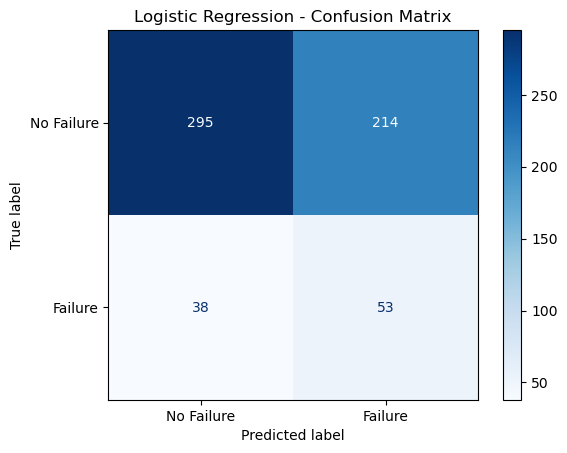

In [65]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# RANDOM FOREST

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [73]:
r_f_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

In [74]:
r_f_model = r_f_model.fit(X_train, y_train)

In [75]:
y_pred_rf = r_f_model.predict(X_test)
y_prob_rf = r_f_model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [76]:
y_pred_rf = r_f_model.predict(X_test)

y_prob_rf = r_f_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")
print("Predicted labels:")
print(pd.Series(y_pred_rf).value_counts())

Predictions completed!
Predicted labels:
0    594
1      6
Name: count, dtype: int64


In [77]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.2%}")
print(f"Precision: {precision_score(y_test, y_pred_rf, zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, zero_division=0):.2%}")
print(f"F1-Score:  {f1_score(y_test, y_pred_rf, zero_division=0):.2%}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.2%}")

Accuracy:  85.50%
Precision: 83.33%
Recall:    5.49%
F1-Score:  10.31%
ROC-AUC:   58.76%


Random Forest Confusion Matrix:
[[508   1]
 [ 86   5]]


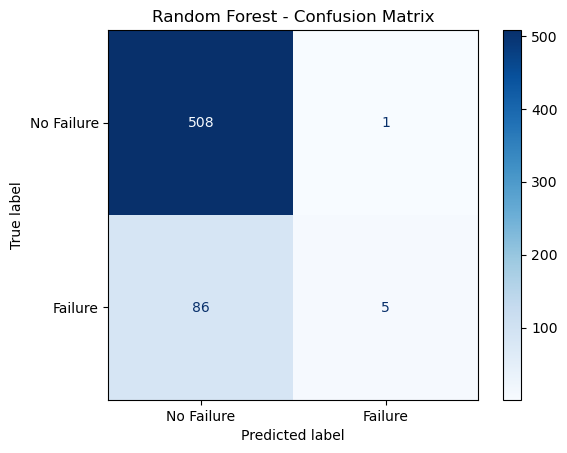

In [79]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.show()